In [1]:
#from google.colab import files
#uploaded = files.upload()

In [2]:
import pandas as pd
import numpy as np

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [6]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [8]:
df = pd.read_csv("adult.csv")
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (32561, 15)
   age workclass  fnlwgt     education  education.num marital.status  \
0   90         ?   77053       HS-grad              9        Widowed   
1   82   Private  132870       HS-grad              9        Widowed   
2   66         ?  186061  Some-college             10        Widowed   
3   54   Private  140359       7th-8th              4       Divorced   
4   41   Private  264663  Some-college             10      Separated   

          occupation   relationship   race     sex  capital.gain  \
0                  ?  Not-in-family  White  Female             0   
1    Exec-managerial  Not-in-family  White  Female             0   
2                  ?      Unmarried  Black  Female             0   
3  Machine-op-inspct      Unmarried  White  Female             0   
4     Prof-specialty      Own-child  White  Female             0   

   capital.loss  hours.per.week native.country income  
0          4356              40  United-States  <=50K  
1          4356    

In [9]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB
None


In [10]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [11]:
print(df.isnull().sum())
print(df["income"].value_counts())

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64
income
<=50K    24720
>50K      7841
Name: count, dtype: int64


In [12]:
df = df.copy()

In [13]:
df.columns = df.columns.str.strip()

In [14]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_5820\1126013313.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [15]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace("?", "Unknown")

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_5820\2304366161.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [16]:
print("Dataset shape:", df.shape)

Dataset shape: (32561, 15)


In [17]:
print(df.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64


In [18]:
print("Unknown values:")
for col in df.select_dtypes(include="object").columns:
    print(col, (df[col] == "Unknown").sum())

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_5820\2603961585.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


Unknown values:
workclass 1836
education 0
marital.status 0
occupation 1843
relationship 0
race 0
sex 0
native.country 583
income 0


In [19]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 24


In [20]:
df = df.drop_duplicates()

In [21]:
print("Duplicates after removal:", df.duplicated().sum())
print("Dataset shape after removing duplicates:", df.shape)

Duplicates after removal: 0
Dataset shape after removing duplicates: (32537, 15)


In [22]:
for col in ["workclass", "occupation", "native.country"]:
    print("\n", col)
    print(pd.crosstab(
        df[col].fillna("Unknown"),
        df["income"],
        normalize="index"
    ).round(3).head(10))


 workclass
income            <=50K   >50K
workclass                     
Federal-gov       0.614  0.386
Local-gov         0.705  0.295
Never-worked      1.000  0.000
Private           0.781  0.219
Self-emp-inc      0.443  0.557
Self-emp-not-inc  0.715  0.285
State-gov         0.728  0.272
Unknown           0.896  0.104
Without-pay       1.000  0.000

 occupation
income             <=50K   >50K
occupation                     
Adm-clerical       0.865  0.135
Armed-Forces       0.889  0.111
Craft-repair       0.773  0.227
Exec-managerial    0.516  0.484
Farming-fishing    0.884  0.116
Handlers-cleaners  0.937  0.063
Machine-op-inspct  0.876  0.124
Other-service      0.958  0.042
Priv-house-serv    0.993  0.007
Prof-specialty     0.551  0.449

 native.country
income              <=50K   >50K
native.country                  
Cambodia            0.632  0.368
Canada              0.678  0.322
China               0.733  0.267
Columbia            0.966  0.034
Cuba                0.737  0.263
Do

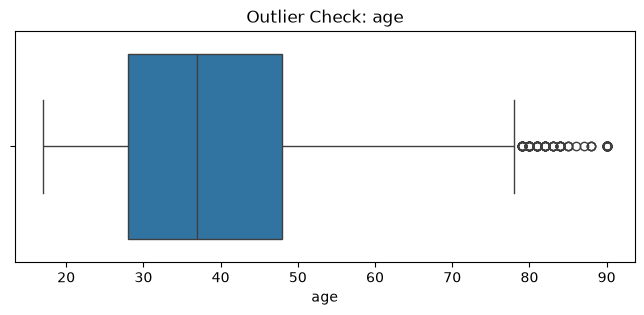

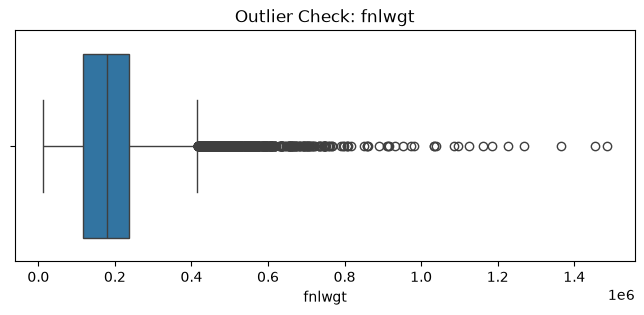

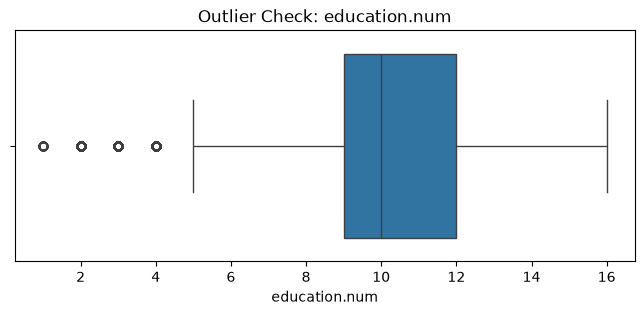

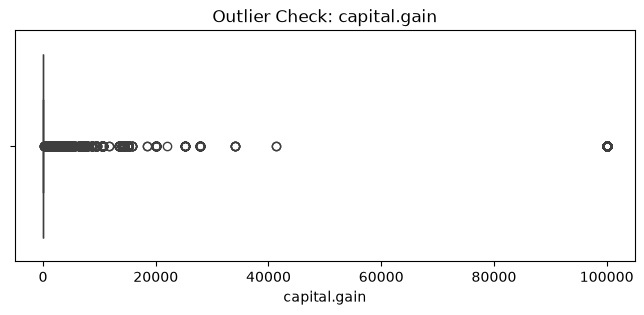

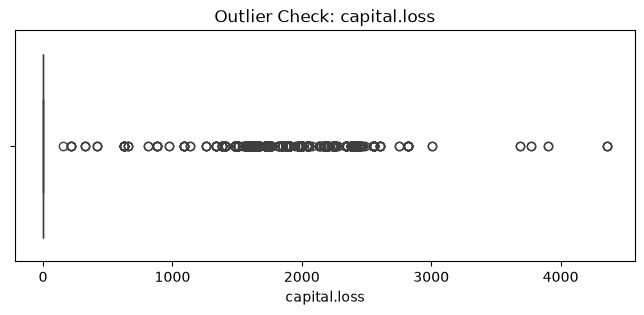

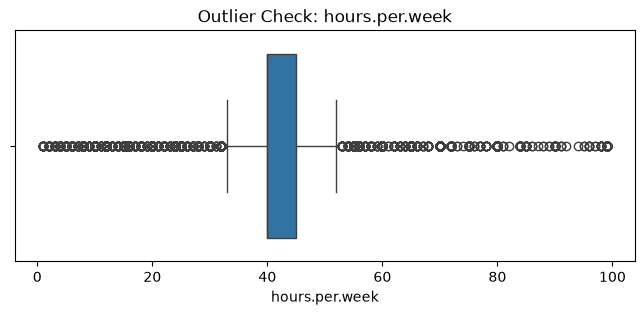

In [23]:
num_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title("Outlier Check: " + col)
    plt.show()

In [24]:
outlier_results = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

        Column  Lower Bound  Upper Bound  Flagged Values
           age         -2.0         78.0             142
        fnlwgt     -60922.0     415742.0             993
 education.num          4.5         16.5            1193
  capital.gain          0.0          0.0            2712
  capital.loss          0.0          0.0            1519
hours.per.week         32.5         52.5            9002


In [25]:
print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())

Minimum age: 17
Maximum age: 90


In [26]:
X = df.drop("income", axis=1)
y = df["income"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (32537, 14)
Target shape: (32537,)


In [27]:
num_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [28]:
cat_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_5820\460086772.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(


In [29]:
print("Numerical columns:", num_cols)

Numerical columns: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']


In [30]:
print("Categorical columns:", cat_cols)

Categorical columns: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [32]:
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 26029
Testing rows: 6508


In [33]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

In [34]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

In [35]:
results = []
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, pos_label=">50K", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, pos_label=">50K", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, pos_label=">50K", zero_division=0
    )
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2)
    })

In [36]:
print("\n", "=" * 50)
print("Model:", name)
print("=" * 50)
print("\nClassification Report:")
print(classification_report(
      y_test,
      y_pred,
      labels=["<=50K", ">50K"],
      target_names=["Income <=50K", "Income >50K"],
      zero_division=0
    ))


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

Income <=50K       0.88      0.93      0.91      4940
 Income >50K       0.74      0.60      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.77      0.78      6508
weighted avg       0.85      0.85      0.85      6508



In [37]:
cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["<=50K", ">50K"]
    )

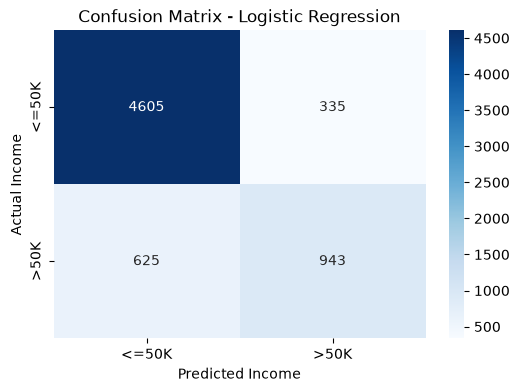

In [38]:
plt.figure(figsize=(6, 4))
sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"]
    )
plt.title("Confusion Matrix - " + name)
plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.show()

In [39]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
)
print("\nFinal Model Comparison:")
print(results_df.to_string(index=False))


Final Model Comparison:
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
Logistic Regression         85.25          73.79       60.14         66.27
      Random Forest         84.60          71.31       60.40         65.40
                KNN         82.61          65.80       57.91         61.60
      Decision Tree         81.19          60.96       61.03         60.99


In [40]:
best_model = results_df.iloc[0]
print("Best Model:", best_model["Model"])

Best Model: Logistic Regression


In [41]:
print("Best Accuracy:", best_model["Accuracy (%)"], "%")

Best Accuracy: 85.25 %


Conclusion

In this project, four machine learning classification algorithms—K-Nearest Neighbors (KNN), Decision Tree, Random Forest, and Logistic Regression—were applied to the Adult Census Income dataset to predict whether an individual's annual income is less than or equal to 50K or greater than 50K.

The dataset was cleaned by handling unknown categorical values without unnecessarily deleting records or features. Categorical variables were encoded, and numerical features were scaled as part of the preprocessing pipeline.

The models were evaluated using the same training and testing split. Logistic Regression achieved the highest accuracy of 85.25%, followed by Random Forest at 84.60%, KNN at 82.61%, and Decision Tree at 81.19%.

Therefore, Logistic Regression was the best-performing model based on accuracy for this particular experiment. However, precision, recall, and F1 score should also be considered before making a final judgment about overall model performance.

In [42]:
import joblib
from sklearn.pipeline import Pipeline

best_model_name = results_df.iloc[0]["Model"]
print("Selected model:", best_model_name)
final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", models[best_model_name])
])
final_model.fit(X, y)
joblib.dump(final_model, "best_model.pkl")
print("Model saved successfully!")

Selected model: Logistic Regression
Model saved successfully!


In [43]:
import os

print("Current folder:", os.getcwd())
print("Model file exists:", os.path.exists("best_model.pkl"))

Current folder: c:\Users\Bhoomi\OneDrive\Desktop\Probation-Project-26\Bhoomika-Task-10
Model file exists: True
